In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
column_names = ['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'target']

ds = pd.read_csv("car.data", sep=",", header=None, names=column_names)
print(ds.head())

X = ds.drop(columns=['target'])
y = ds['target']

  buying  maint doors persons lug_boot safety target
0  vhigh  vhigh     2       2    small    low  unacc
1  vhigh  vhigh     2       2    small    med  unacc
2  vhigh  vhigh     2       2    small   high  unacc
3  vhigh  vhigh     2       2      med    low  unacc
4  vhigh  vhigh     2       2      med    med  unacc


In [3]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Encoded Classes:", label_encoder.classes_)

Encoded Classes: ['acc' 'good' 'unacc' 'vgood']


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.ensemble import RandomForestClassifier

categorical_features = X.columns.tolist()

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(handle_unknown='error'))
])

preprocessor = ColumnTransformer(transformers=[
    ('cat', categorical_pipeline, categorical_features)
])

final_model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, criterion='entropy', random_state=0, n_jobs=-1))
])

In [5]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.25, random_state=0, stratify=y_encoded)

final_model_pipeline.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [6]:
y_pred = final_model_pipeline.predict(X_test)

In [7]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

cm = confusion_matrix(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)
print(f"Random Forest Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))

Random Forest Accuracy: 97.22%

Classification Report:
              precision    recall  f1-score   support

         acc       0.92      0.96      0.94        96
        good       1.00      0.88      0.94        17
       unacc       0.99      0.98      0.99       303
       vgood       1.00      0.94      0.97        16

    accuracy                           0.97       432
   macro avg       0.98      0.94      0.96       432
weighted avg       0.97      0.97      0.97       432



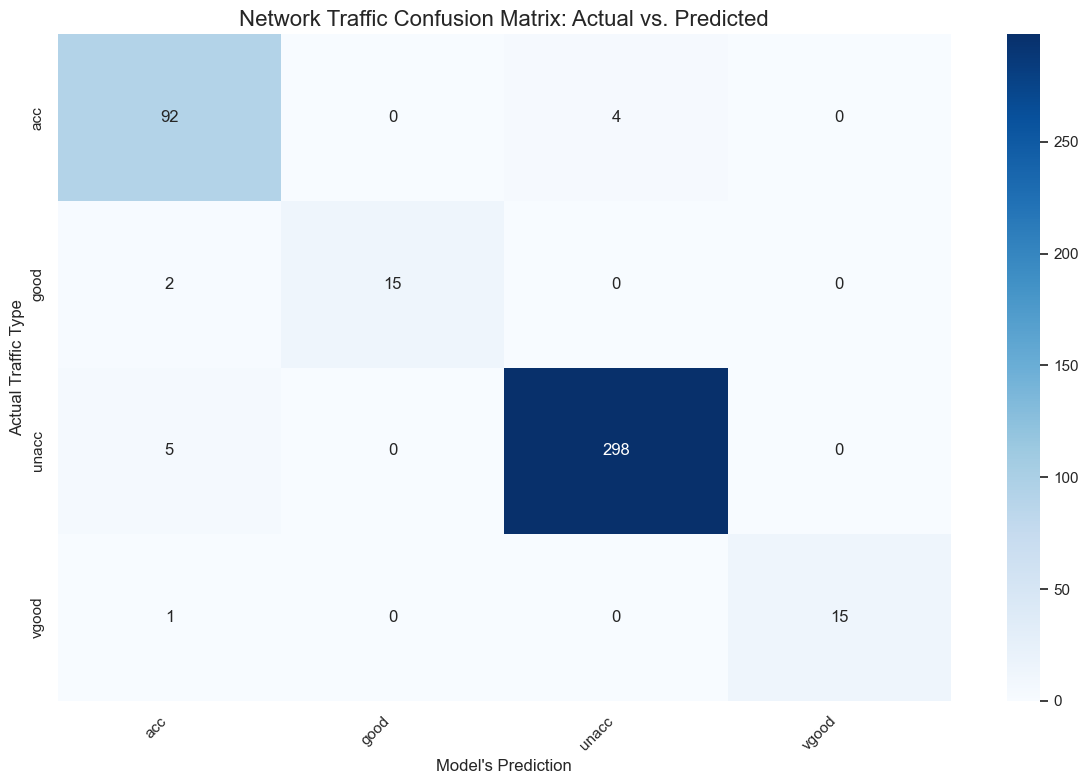

In [8]:
plt.figure(figsize=(12, 8))
sns.set_theme(style="white") # Cleaner background for heatmaps

# fmt='d' ensures the numbers print as whole integers, not scientific notation
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=label_encoder.classes_, 
            yticklabels=label_encoder.classes_)

plt.title("Network Traffic Confusion Matrix: Actual vs. Predicted", fontsize=16)
plt.ylabel("Actual Traffic Type", fontsize=12)
plt.xlabel("Model's Prediction", fontsize=12)

# Rotate the bottom labels so they don't overlap
plt.xticks(rotation=45, ha='right') 
plt.tight_layout()
plt.show()